# 42 — Comparaison des méthodes temporelle et spatiale

Lit les deux tables par leg de la collection, `legs/relut_by_leg.parquet` (notebook 32) et `legs/spatial_by_leg.parquet` (notebook 22), construites sur le **même corpus commun** de legs, et compare leg par leg :

1. les **histogrammes superposés** des durées et des distances de cruising des deux méthodes ;
2. un **nuage de points** temporel (x) vs spatial (y), avec la **régression linéaire** (moindres carrés) et la diagonale y = x, pour les durées puis pour les distances ;
3. un **tableau de corrélations** : Pearson (relation linéaire) et Spearman (relation de rang, robuste aux valeurs extrêmes), p-valeurs, pente et ordonnée de la régression, médianes.

**Population** : `both_evaluated` = legs évaluées par les deux méthodes (les legs sans cruising comptent pour 0) ; `both_detected` = cruising détecté par les deux ; `either_detected` = détecté par au moins une.

**Mesures** : temporel = durée et distance parcourue depuis la bascule ReLUT ; spatial = `spatial_search_*` (détour routé ou apparié si disponible, sinon fenêtre du cercle, selon `search_measure` du notebook 22). D'autres colonnes peuvent être choisies dans les paramètres (ex. temps et distance dans le cercle, distance excessive sur trace appariée).

Logique : `src/parking_search_prediction/method_comparison.py`.

In [13]:
CONFIG_NAME = "full_waypoints.yaml"
OUTPUT_DIR = "outputs/pl23"

POPULATION = "both_detected"     # "both_evaluated", "both_detected" ou "either_detected"

# Colonnes comparées (secondes pour les durées, mètres pour les distances)
RELUT_DURATION = "relut_search_duration_s"
RELUT_DISTANCE = "relut_search_distance_m"          # ou "relut_straight_line_distance_m"
SPATIAL_DURATION = "spatial_search_duration_s"      # ou "spatial_window_duration_s"
SPATIAL_DISTANCE = "spatial_search_distance_m"      # ou "spatial_window_distance_m", "spatial_dist_excess_matched_m"

population          legs avec cruising détecté par les deux méthodes
legs                                                            4856
relut_duration                               relut_search_duration_s
relut_distance                               relut_search_distance_m
spatial_duration                           spatial_search_duration_s
spatial_distance                           spatial_search_distance_m
Name: comparaison, dtype: object

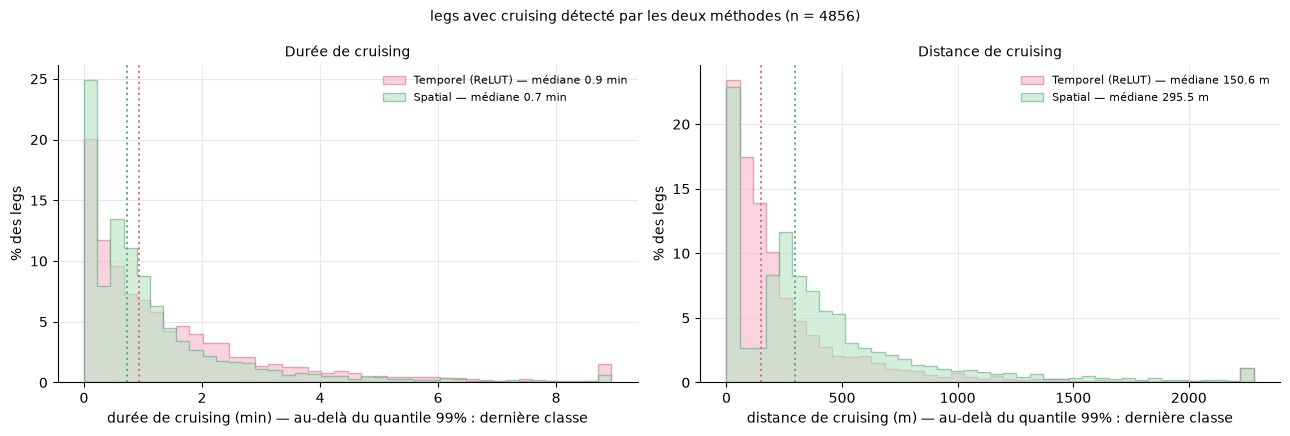

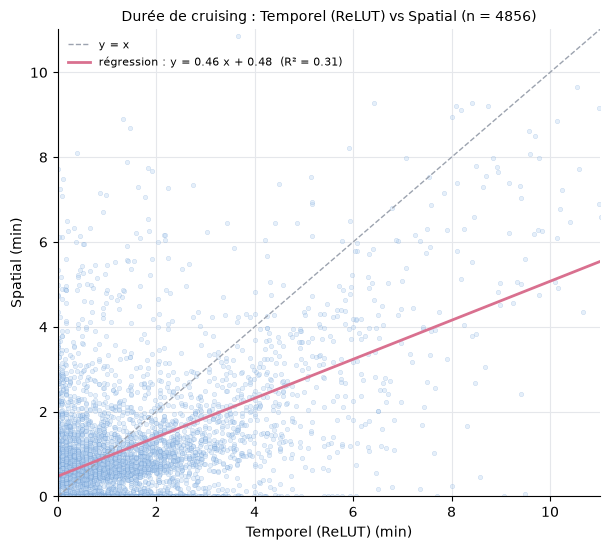

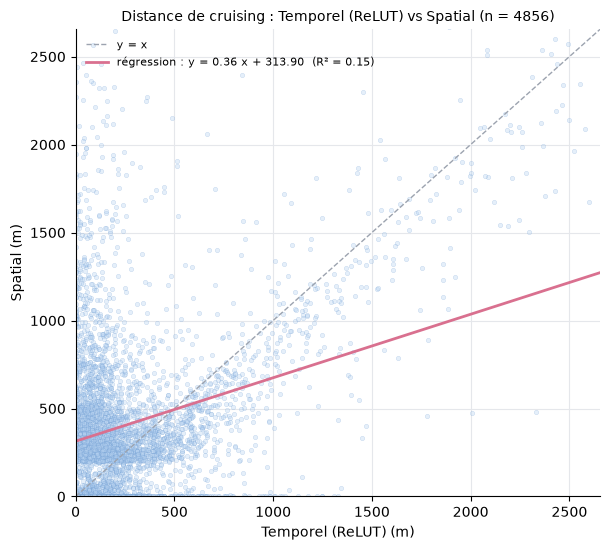

In [14]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from parking_search_prediction.config import load_config
from parking_search_prediction.method_comparison import POPULATIONS, correlation_table, load_comparison, run_comparison

config = load_config(PROJECT_ROOT / "config" / CONFIG_NAME)
config["paths"]["output_dir"] = OUTPUT_DIR
columns = dict(relut_duration=RELUT_DURATION, relut_distance=RELUT_DISTANCE,
               spatial_duration=SPATIAL_DURATION, spatial_distance=SPATIAL_DISTANCE)
result = run_comparison(config, population=POPULATION, **columns)
pd.Series({"population": POPULATIONS[POPULATION], "legs": len(result["comparison"]), **columns}, name="comparaison")

## Histogrammes superposés

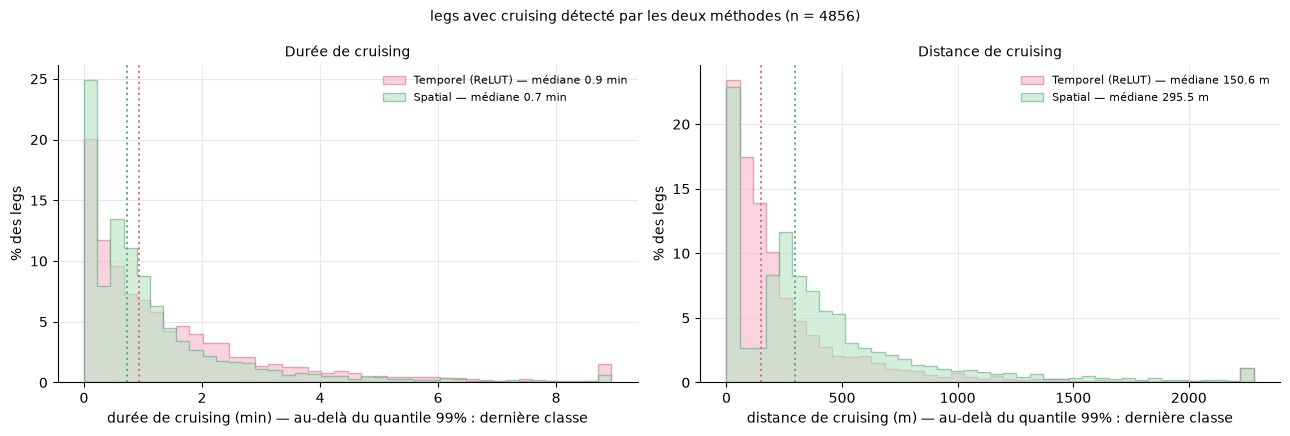

In [15]:
display(result["figures"]["histograms"])
plt.close(result["figures"]["histograms"])

## Durées : temporel vs spatial

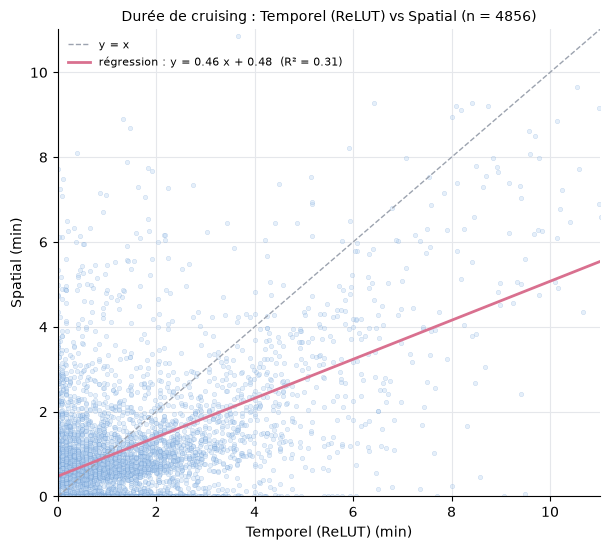

In [16]:
display(result["figures"]["scatter_duration"])
plt.close(result["figures"]["scatter_duration"])

## Distances : temporel vs spatial

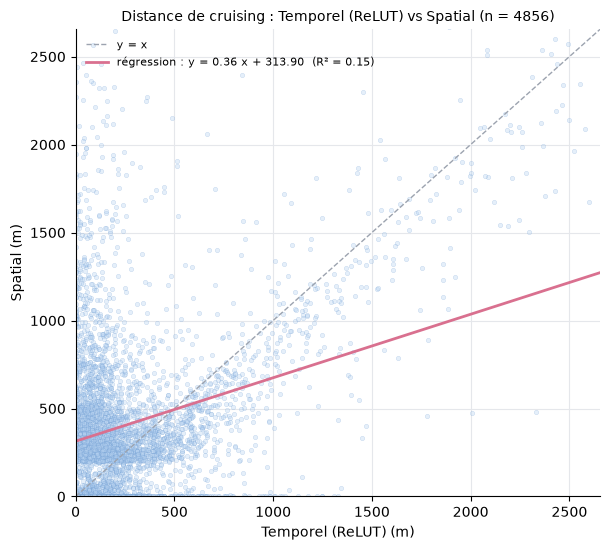

In [17]:
display(result["figures"]["scatter_distance"])
plt.close(result["figures"]["scatter_distance"])

## Corrélations

`pearson_r` mesure l'accord **linéaire** (sensible aux valeurs extrêmes) ; `spearman_rho` mesure si les deux méthodes **classent** les legs dans le même ordre. `pente` / `ordonnee` : régression spatial = pente × temporel + ordonnée. Une pente proche de 1 et une ordonnée proche de 0 signifient que les deux méthodes mesurent la même chose à la même échelle.

In [18]:
display(result["correlations"].round(3))
# Les trois populations côte à côte
pd.concat({name: correlation_table(load_comparison(config, population=name, **columns)) for name in POPULATIONS},
          names=["population"]).droplevel(1).reset_index().round(3)

,grandeur,n_legs,pearson_r,pearson_p,spearman_rho,spearman_p,pente,ordonnee,r2,mediane_temporel,mediane_spatial,ecart_moyen_spatial_moins_temporel
0,durée (min),4856,0.557,0.0,0.371,0.0,0.460,0.477,0.311,0.933,0.732,-0.376
1,distance (m),4856,0.390,0.0,0.215,0.0,0.361,313.896,0.152,150.603,295.516,123.817


,population,grandeur,n_legs,pearson_r,pearson_p,spearman_rho,spearman_p,pente,ordonnee,r2,mediane_temporel,mediane_spatial,ecart_moyen_spatial_moins_temporel
0,both_evaluated,durée (min),35855,0.409,0.0,0.246,0.0,0.235,-0.013,0.167,0.333,0.000,-0.590
1,both_evaluated,distance (m),35855,0.247,0.0,0.256,0.0,0.141,39.560,0.061,62.550,0.000,-71.236
2,both_detected,durée (min),4856,0.557,0.0,0.371,0.0,0.460,0.477,0.311,0.933,0.732,-0.376
3,both_detected,distance (m),4856,0.390,0.0,0.215,0.0,0.361,313.896,0.152,150.603,295.516,123.817
4,either_detected,durée (min),33250,0.404,0.0,0.229,0.0,0.236,-0.015,0.164,0.417,0.000,-0.637
5,either_detected,distance (m),33250,0.242,0.0,0.240,0.0,0.139,43.008,0.059,72.051,0.000,-76.817
